# Первая лабораторная работа: fusion на датасете PMEmo

## Импорты, константы и вспомогательные функции

In [1]:
import json
import random
import re
import warnings
from collections import OrderedDict
from pathlib import Path
from pprint import pp

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Audio, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import classification_report, silhouette_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from tqdm import tqdm
from transformers import (
    BertModel,
    BertTokenizer,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Model,
)

warnings.filterwarnings("ignore")
device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
SR = 16000
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
ENCODING = "utf-8"

In [3]:
AUDIO_CORPUS_PATH = Path("data/PMEmo2019/chorus")
LYRICS_CORPUS_PATH = Path("data/PMEmo2019/lyrics")
ANNOTATIONS = Path("data/PMEmo2019/genre_annotations/genre_annotations.csv")
ARTIST_SONG = "data/PMEmo2019/songs.json"
ARTIST_SONG = "data/PMEmo2019/songs.json"

In [4]:
with open(ARTIST_SONG, "r") as f:
    artists_songs_dict = json.load(f)

In [5]:
annotations_df = pd.read_csv(ANNOTATIONS, sep=",", index_col="musicId")
annotations_df.head()

,genre
musicId,
1,Hip-Hop/Rap
4,Hip-Hop/Rap
5,Hip-Hop/Rap
6,Hip-Hop/Rap
7,Pop


In [6]:
audio_paths = []
text_paths = []
annotations = []

for root, dirs, files in AUDIO_CORPUS_PATH.walk():
    for file in files:
        audio_path = root / file
        try:
            music_id = int(str(Path(file).with_suffix("")))
            annotation = annotations_df.loc[music_id]

            text_path = LYRICS_CORPUS_PATH / Path(file).with_suffix(".lrc")
            if not text_path.exists():
                continue

            audio_paths.append(audio_path)
            text_paths.append(text_path)
            annotations.append(annotation["genre"])
        except KeyError:
            pass

In [7]:
genres = list(OrderedDict.fromkeys(annotations))
pp(genres)

['R&B/Soul',
 'Rock/Alternative',
 'Pop',
 'Hip-Hop/Rap',
 'Country',
 'Dance/Electronic']


In [8]:
genre_to_num = dict.fromkeys(genres)
genre_to_num = {key : idx for idx, key in enumerate(genre_to_num)}
genre_to_num

{'R&B/Soul': 0,
 'Rock/Alternative': 1,
 'Pop': 2,
 'Hip-Hop/Rap': 3,
 'Country': 4,
 'Dance/Electronic': 5}

In [9]:
annotations_nums = [genre_to_num[genre] for genre in annotations]

In [10]:
print(f"Кол-во аудиозаписей: {len(audio_paths)}\nКол-во лейблов: {len(annotations)}")

Кол-во аудиозаписей: 556
Кол-во лейблов: 556


In [11]:
def read_lrc(text_path):
    def lrc_preprocess(line):
        line = line.strip()
        line = re.sub(r"\[.+\]", "", line)
        return line

    with open(text_path) as f:
        lrc_list = f.readlines()
    lrc_list = [lrc_preprocess(lrc_string) for lrc_string in lrc_list]
    lrc_list = list(filter(len, lrc_list))

    return lrc_list

In [16]:
def cut_audio(audio, max_len_sec=30):
    max_len_samples = max_len_sec * SR
    return audio[:max_len_samples]

In [17]:
def draw_spectrogram(audio_path):
    plt.figure(figsize=(6, 3))
    audio, _ = librosa.load(audio_path, duration=15)
    D = librosa.stft(audio)
    S_db = librosa.amplitude_to_db(
        np.abs(D),
        ref=np.max,
        # От максимума до максимума - 60дБ
        top_db=60
    )
    librosa.display.specshow(
        S_db, 
        y_axis='linear', 
        x_axis='time', 
        sr=SR,
        cmap="magma",
    )
    plt.show()

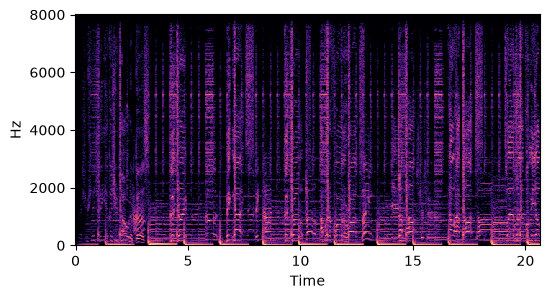

In [18]:
draw_spectrogram("data/PMEmo2019/chorus/1.mp3")

## Извлечение признаков

### wav2vec2

In [19]:
wav2vec2_model = Wav2Vec2Model.from_pretrained(
    "facebook/wav2vec2-base-960h"
)
wav2vec2_model.eval()
wav2vec2_model = wav2vec2_model.to(device) # type: ignore
wav2vec2_feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(
    "facebook/wav2vec2-base-960h"
)

Some weights of Wav2Vec2Model were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [20]:
wav2vec2_embeddings = []
for audio_path in tqdm(audio_paths):
    audio, _ = librosa.load(audio_path, sr=SR)
    audio = cut_audio(audio)

    # # -> [[window], [window]]
    # audio = make_audio_windows(audio)

    inputs = wav2vec2_feature_extractor(
        audio,
        sampling_rate=SR,
        return_tensors="pt",
        padding=True
    )
    inputs = inputs.to(device)

    with torch.inference_mode():
        outputs = wav2vec2_model(**inputs)

    features = outputs.last_hidden_state
    embedding = features.mean(dim=1).squeeze(0).to("cpu")

    wav2vec2_embeddings.append(embedding)

100%|██████████| 556/556 [04:05<00:00,  2.26it/s]


In [21]:
wav2vec2_embeddings[0].shape

torch.Size([768])

In [22]:
torch.save(wav2vec2_embeddings, "embeddings/wav2vec2_embeddings.pt")

### BERT

In [23]:
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased")
bert_model.eval()
bert_model = bert_model.to(device) # type: ignore

In [24]:
bert_embeddings = []
for text_path in tqdm(text_paths):
    # -> [[lyrics line], [lyrics line]]
    text = read_lrc(text_path)
    # text = "\n".join(read_lrc(text_path))
    
    inputs = bert_tokenizer(
        text,
        return_tensors="pt",
        padding=True
    )
    inputs = inputs.to(device)

    with torch.inference_mode():
        outputs = bert_model(
            **inputs, 
            output_hidden_states=True
        )

    features = outputs.last_hidden_state
    embedding = features.mean(dim=0).mean(dim=0).to("cpu")    

    bert_embeddings.append(embedding)

100%|██████████| 556/556 [01:44<00:00,  5.32it/s]


In [25]:
bert_embeddings[0].shape

torch.Size([768])

In [26]:
torch.save(bert_embeddings, "embeddings/bert_embeddings.pt")

## EDA

### Аудио

In [27]:
colors = {
    "Country": "red",
    "Dance/Electronic": "blue",
    "Hip-Hop/Rap": "orange",
    "Pop": "purple",
    "R&B/Soul": "green",
    "Rock/Alternative": "black",
}

In [28]:
audio_embeddings = torch.load("embeddings/audio_feature_vectors.pt")

In [29]:
scaler = StandardScaler()
audio_embeddings = scaler.fit_transform(audio_embeddings)

In [30]:
pca = PCA(n_components=2)
audio_emb_PCA = pca.fit_transform(audio_embeddings)
audio_emb_PCA_X = [emb[0] for emb in audio_emb_PCA]
audio_emb_PCA_Y = [emb[1] for emb in audio_emb_PCA]

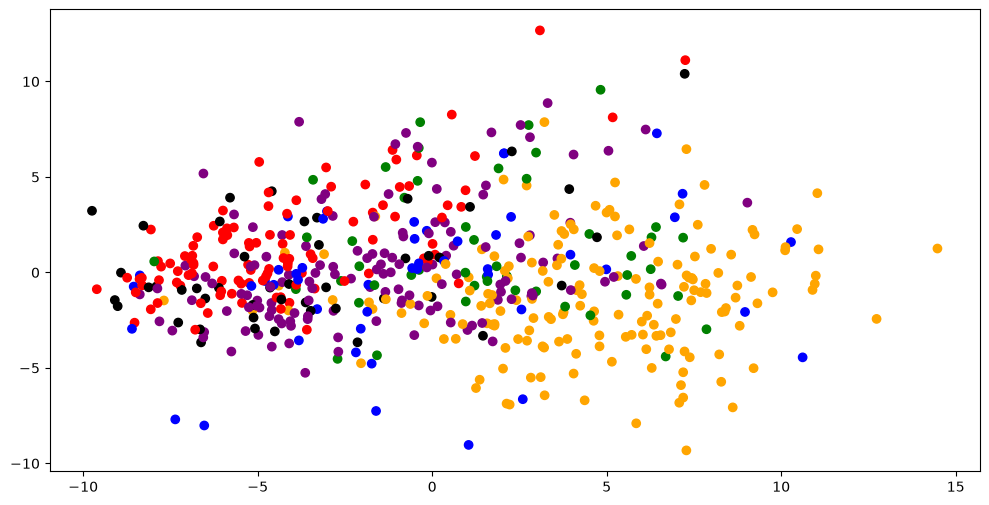

In [31]:
plt.figure(figsize=(12, 6))
plt.scatter(
    audio_emb_PCA_X, 
    audio_emb_PCA_Y,
    c=[colors[genre] for genre in annotations]
)
plt.show()

In [32]:
silhouette_val = silhouette_score(audio_embeddings, annotations)
print("Silhouette:", silhouette_val)

Silhouette: -0.01231098042538243


In [33]:
clusters = KMeans(
    n_clusters=len(genres),
    random_state=RANDOM_STATE,
).fit_predict(audio_embeddings)

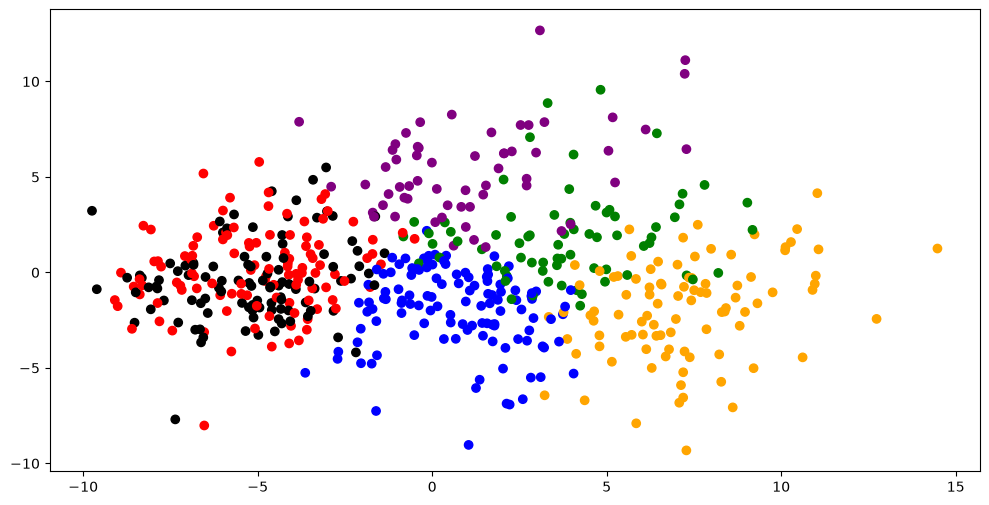

In [34]:
plt.figure(figsize=(12, 6))
plt.scatter(
    audio_emb_PCA_X, 
    audio_emb_PCA_Y,
    c=[list(colors.values())[cluster] for cluster in clusters]
)
plt.show()

In [35]:
def get_n_cluster_examples(annotations, cluster_name, n=3):
    indices = [i for i, x in enumerate(annotations) if x == cluster_name]
    # return [random.choice(indices) for _ in range(n)]
    return indices[:n]

Аудио для кластера 0

Песня: Lights Come On, исполнитель: Jason Aldean



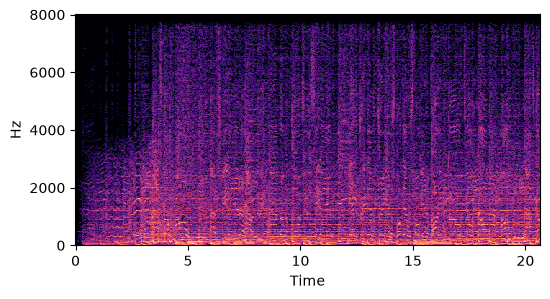


Песня: Once, исполнитель: Maren Morris



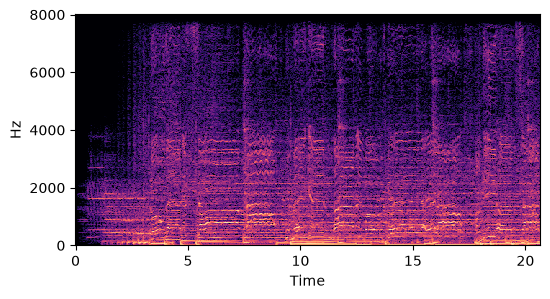


Песня: How Not To, исполнитель: Dan + Shay



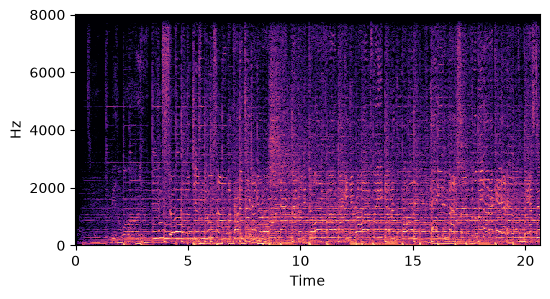




Аудио для кластера 1

Песня: Don't Touch My Hair, исполнитель: Solange



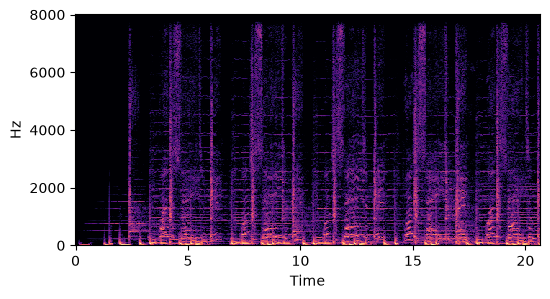


Песня: Feel It Still, исполнитель: Portugal. The Man



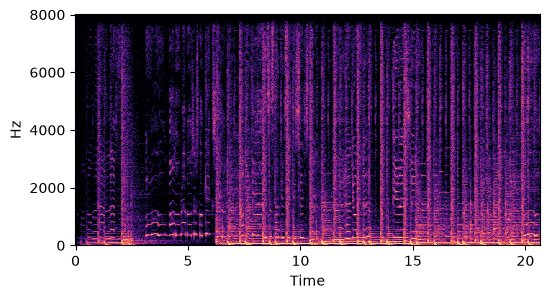


Песня: Somethin' I'm Good At, исполнитель: Brett Eldredge



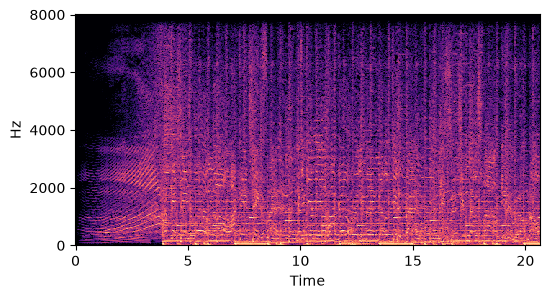




Аудио для кластера 2

Песня: Gyalchester, исполнитель: Drake



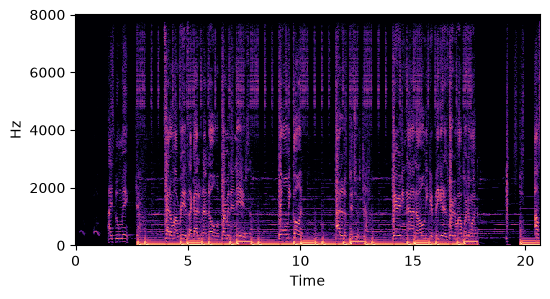


Песня: The Heart Part 4, исполнитель: Kendrick Lamar



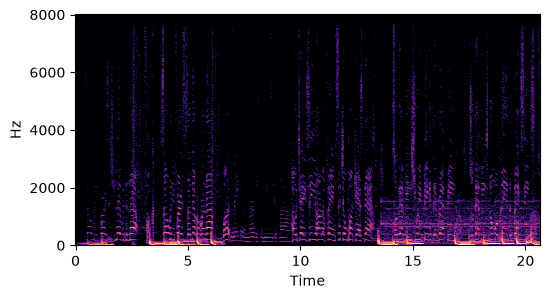


Песня: Uber Everywhere, исполнитель: MadeinTYO



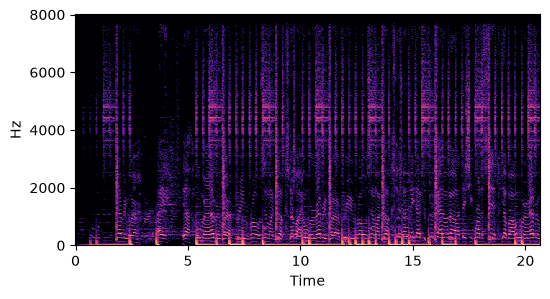




Аудио для кластера 3

Песня: Ain't No Grave (Album Version), исполнитель: Johnny Cash



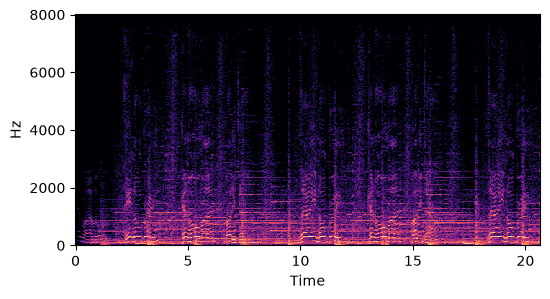


Песня: Drinkin' Too Much (8pm), исполнитель: Sam Hunt



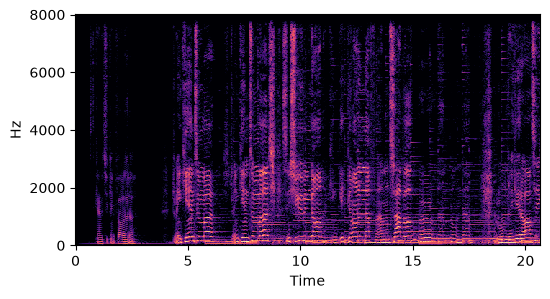


Песня: Broadway+For+Orlando, исполнитель: Various Artists



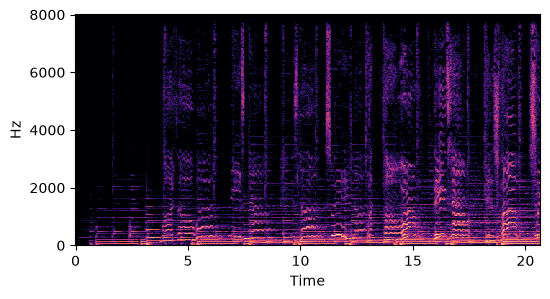




Аудио для кластера 4

Песня: Everyday We Lit, исполнитель: YFN Lucci



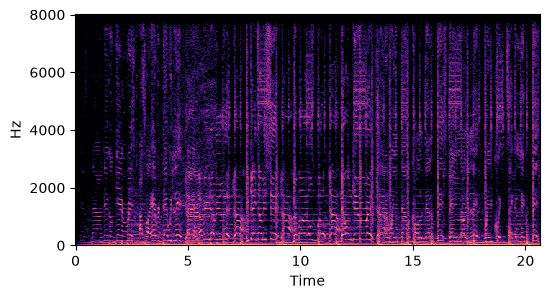


Песня: Keep The Family Close, исполнитель: Drake



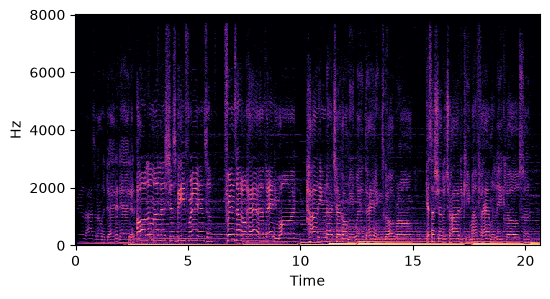


Песня: False Prophets, исполнитель: J. Cole



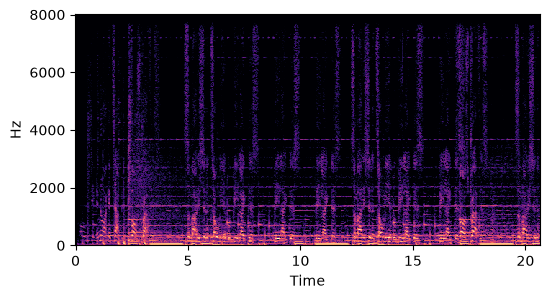




Аудио для кластера 5

Песня: 02 Wish I Knew You, исполнитель: The Revivalists



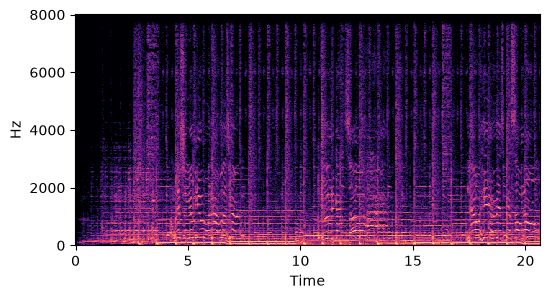


Песня: Not Easy, исполнитель: Alex Da Kid



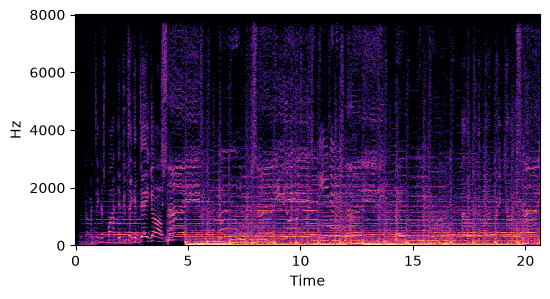


Песня: You Look Good, исполнитель: Lady Antebellum



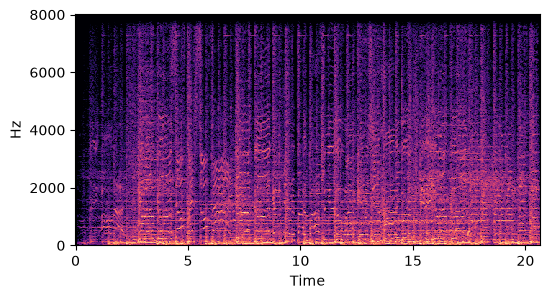

In [36]:
cluster_names = set(clusters)
for cluster_name in cluster_names:
    idxs = get_n_cluster_examples(clusters, cluster_name)

    print(f"Аудио для кластера {cluster_name}")
    print()

    for idx in idxs:
        audio_path = audio_paths[idx]
        audio_numb = audio_path.stem

        song_info = artists_songs_dict[audio_numb]
        print(f"Песня: {song_info["title"]}, исполнитель: {song_info["artist"]}")
        print()
        
        display(Audio(filename=audio_path))
        draw_spectrogram(audio_path)

        print()
    print("\n")

### Текст

In [37]:
text_embeddings = torch.load("embeddings/bert_embeddings.pt")

In [38]:
scaler = StandardScaler()
text_embeddings = scaler.fit_transform(text_embeddings)

In [39]:
colors = {
    "Country": "red",
    "Dance/Electronic": "blue",
    "Hip-Hop/Rap": "orange",
    "Pop": "purple",
    "R&B/Soul": "green",
    "Rock/Alternative": "black",
}

In [40]:
pca = PCA(n_components=2)
text_emb_PCA = pca.fit_transform(text_embeddings)
text_emb_PCA_X = [emb[0] for emb in text_emb_PCA]
text_emb_PCA_Y = [emb[1] for emb in text_emb_PCA]

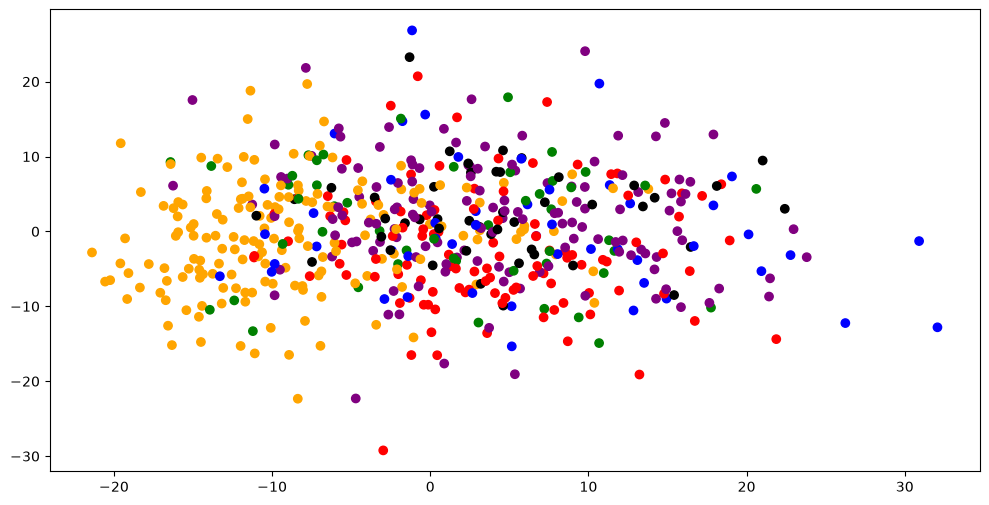

In [41]:
plt.figure(figsize=(12, 6))
plt.scatter(
    text_emb_PCA_X, 
    text_emb_PCA_Y,
    c=[colors[genre] for genre in annotations]
)
plt.show()

In [42]:
silhouette_val = silhouette_score(text_embeddings, annotations)
print("Silhouette:", silhouette_val)

Silhouette: -0.001569989255167911


In [43]:
clusters = KMeans(
    n_clusters=len(genres),
    random_state=RANDOM_STATE,
).fit_predict(text_embeddings)

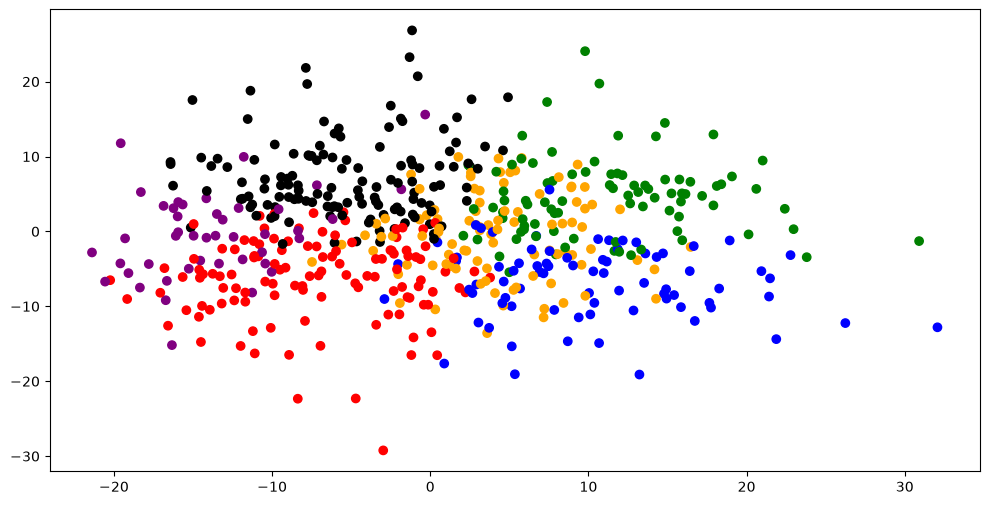

In [44]:
plt.figure(figsize=(12, 6))
plt.scatter(
    text_emb_PCA_X, 
    text_emb_PCA_Y,
    c=[list(colors.values())[cluster] for cluster in clusters]
)
plt.show()

In [45]:
def get_n_cluster_examples(annotations, cluster_name, n=3):
    indices = [i for i, x in enumerate(annotations) if x == cluster_name]
    # return [random.choice(indices) for _ in range(n)]
    return indices[:n]

In [46]:
cluster_names = set(clusters)
for cluster_name in cluster_names:
    idxs = get_n_cluster_examples(clusters, cluster_name)

    print(f"Тексты для кластера {cluster_name}")
    print()

    for idx in idxs:
        text_path = text_paths[idx]
        text_numb = text_path.stem

        song_info = artists_songs_dict[text_numb]

        print(f"Песня: {song_info["title"]}, исполнитель: {song_info["artist"]}")
        print()

        text = read_lrc(text_path)
        text_middle = len(text) // 2

        print("\n".join(text[text_middle : text_middle + 7]))
        print()
    print("\n")

Тексты для кластера 0

Песня: Gyalchester, исполнитель: Drake

They want me gone, out of the picture
Bury me now and I only get bigger, that's word to my, word to my
I'm so hot yeah, I’m so right now
Who's not gang bitch? Let me find out
Keep hearing clicks when I'm talkin' on the iPhone
Feds in the city hate to see us on a high note
I switch flow like I switch time zone

Песня: Ain't No Grave (Album Version), исполнитель: Johnny Cash

There ain't no grave can hold my body down
Ain't no grave can hold my body down
Well  meet me  Jesus  meet me  meet me in the middle of the air
And if these wings don't fail me I will meet you anywhere
Ain't no grave can hold my body down
There ain't no grave can hold my body down
Well  meet me mother and father  meet me down the river road

Песня: The Heart Part 4, исполнитель: Kendrick Lamar

Blacks that act white, Whites that do the dab
Donald Trump is a chump, know how we feel, punk
Tell 'em that God comin'
And Russia need a replay button, y'all up t

## Классификаторы по отдельности

### Аудио

In [47]:
audio_embeddings = torch.load("embeddings/wav2vec2_embeddings.pt")

In [48]:
audio_vectors_train, audio_vectors_test, \
    annotations_train, annotations_test = train_test_split(
        audio_embeddings,
        annotations, 
        test_size=0.2, 
        random_state=RANDOM_STATE
)

In [49]:
rfc = RandomForestClassifier(
    random_state=RANDOM_STATE
)
params = {
    "n_estimators": [100, 300],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(
    rfc,
    params,
    cv=5,
    n_jobs=-1,
    verbose=1,
    scoring="f1_macro",
)

In [50]:
grid.fit(audio_vectors_train, annotations_train)
best_estimator = grid.best_estimator_

Fitting 5 folds for each of 64 candidates, totalling 320 fits


In [51]:
rfc_preds = best_estimator.predict(audio_vectors_test)
print(classification_report(annotations_test, rfc_preds))

                  precision    recall  f1-score   support

         Country       0.38      0.58      0.46        19
Dance/Electronic       0.17      0.07      0.10        15
     Hip-Hop/Rap       0.68      0.82      0.75        34
             Pop       0.16      0.12      0.14        25
        R&B/Soul       0.00      0.00      0.00        12
Rock/Alternative       0.00      0.00      0.00         7

        accuracy                           0.38       112
       macro avg       0.23      0.26      0.24       112
    weighted avg       0.33      0.38      0.35       112



In [52]:
joblib.dump(best_estimator, "models/audio_classifier.joblib")

['models/audio_classifier.joblib']

### Текст

In [53]:
text_embeddings = torch.load("embeddings/bert_embeddings.pt")

In [54]:
text_embeddings_train, text_embeddings_test, \
    annotations_train, annotations_test = train_test_split(
        text_embeddings,
        annotations, 
        test_size=0.2, 
        random_state=RANDOM_STATE
)

In [55]:
text_embeddings_train[0].shape, annotations_train[0]

(torch.Size([768]), 'Country')

In [56]:
rfc = RandomForestClassifier(
    random_state=RANDOM_STATE
)
params = {
    "n_estimators": [100, 300],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(
    rfc,
    params,
    cv=5,
    n_jobs=-1,
    verbose=1,
    scoring="f1_macro",
)

In [57]:
grid.fit(text_embeddings_train, annotations_train)
best_estimator = grid.best_estimator_

Fitting 5 folds for each of 64 candidates, totalling 320 fits


In [58]:
rfc_preds = best_estimator.predict(text_embeddings_test)
print(classification_report(annotations_test, rfc_preds))

                  precision    recall  f1-score   support

         Country       0.45      0.68      0.54        19
Dance/Electronic       0.33      0.13      0.19        15
     Hip-Hop/Rap       0.81      0.85      0.83        34
             Pop       0.39      0.44      0.42        25
        R&B/Soul       0.00      0.00      0.00        12
Rock/Alternative       0.22      0.29      0.25         7

        accuracy                           0.51       112
       macro avg       0.37      0.40      0.37       112
    weighted avg       0.47      0.51      0.48       112



In [59]:
joblib.dump(best_estimator, "models/text_classifier.joblib")

['models/text_classifier.joblib']

## Fusion

### Early Fusion

In [60]:
audio_embeddings = torch.load("embeddings/wav2vec2_embeddings.pt")
text_embeddings = torch.load("embeddings/bert_embeddings.pt")

early_fused_embs = []
for audio_emb, text_emb in zip(audio_embeddings, text_embeddings):
    early_fused_embs.append(
        torch.cat((audio_emb, text_emb))
    )

In [61]:
len(early_fused_embs), len(annotations)

(556, 556)

In [62]:
early_fused_embs_train, early_fused_embs_test, \
    annotations_train, annotations_test = train_test_split(
        early_fused_embs,
        annotations
    )

In [63]:
scaler = StandardScaler()
early_fused_embs_train = scaler.fit_transform(early_fused_embs_train)
early_fused_embs_test = scaler.transform(early_fused_embs_test)

In [64]:
rfc = RandomForestClassifier(
    random_state=RANDOM_STATE
)
params = {
    "n_estimators": [100, 300],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(
    rfc,
    params,
    cv=5,
    n_jobs=-1,
    verbose=1,
    scoring="f1_macro",
)

In [65]:
grid.fit(early_fused_embs_train, annotations_train)
best_estimator = grid.best_estimator_

Fitting 5 folds for each of 64 candidates, totalling 320 fits


In [66]:
rfc_preds = best_estimator.predict(early_fused_embs_test)
print(classification_report(annotations_test, rfc_preds))

                  precision    recall  f1-score   support

         Country       0.70      0.79      0.74        33
Dance/Electronic       0.40      0.20      0.27        10
     Hip-Hop/Rap       0.71      0.80      0.75        40
             Pop       0.44      0.59      0.50        29
        R&B/Soul       0.00      0.00      0.00        13
Rock/Alternative       0.29      0.14      0.19        14

        accuracy                           0.57       139
       macro avg       0.42      0.42      0.41       139
    weighted avg       0.52      0.57      0.54       139



### Intermedeate Fusion

In [104]:
audio_embeddings = torch.stack(
    torch.load("embeddings/wav2vec2_embeddings.pt")
)

text_embeddings = torch.stack(
    torch.load("embeddings/bert_embeddings.pt")
)

labels = torch.tensor(annotations_nums)

In [105]:
audio_embeddings.shape, text_embeddings.shape

(torch.Size([556, 768]), torch.Size([556, 768]))

In [106]:
audio_train, audio_test, text_train, text_test, y_train, y_test = train_test_split(
    audio_embeddings,
    text_embeddings,
    labels,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=labels
)

In [107]:
class IntermediateFusion(nn.Module):
    def __init__(
            self, 
            n_genres,
            audio_dim,
            text_dim
        ):
        super().__init__()

        self.audio_proj = nn.Linear(audio_dim, 256)
        self.text_proj = nn.Linear(text_dim, 256)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256,
            nhead=8,
            batch_first=True,
        )

        self.fusion = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 256),
            # nn.LayerNorm(256),
            nn.GELU(),

            nn.Linear(256, 128),
            # nn.LayerNorm(128),
            nn.GELU(),

            nn.Dropout(0.3),

            nn.Linear(128, n_genres)
        )

    def forward(self, audio_emb, text_emb):
        audio_emb = self.audio_proj(audio_emb)
        text_emb = self.text_proj(text_emb)

        x = torch.stack(
            [audio_emb, text_emb],
            dim=1
        )

        x = self.fusion(x)

        x = x.mean(dim=1)

        logits = self.classifier(x)

        return logits

In [108]:
model = IntermediateFusion(
    len(genres),
    audio_embeddings.shape[1],
    text_embeddings.shape[1],
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [109]:
loss_epochs = []
for epoch in tqdm(range(150)):

    optimizer.zero_grad()

    logits = model(
        audio_train, 
        text_train
    )

    loss = criterion(
        logits,
        y_train
    )

    loss.backward()

    optimizer.step()

    loss_epochs.append(loss.item())

100%|██████████| 150/150 [00:28<00:00,  5.29it/s]


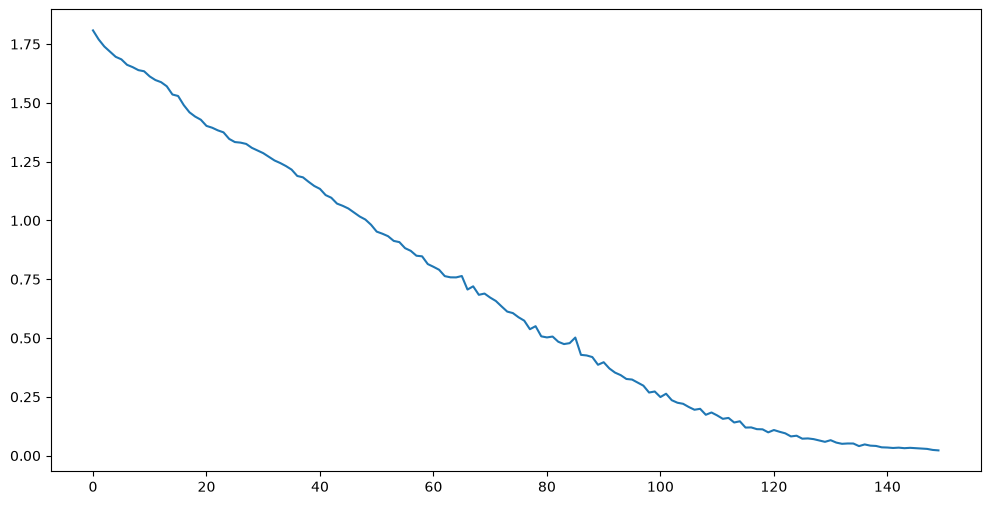

In [110]:
plt.figure(figsize=(12, 6))
plt.plot(loss_epochs)
plt.show()

In [111]:
with torch.inference_mode():
    logits = model(audio_test, text_test)
preds = torch.argmax(logits, dim=1)
print(classification_report(y_test, preds))

              precision    recall  f1-score   support

           0       0.09      0.10      0.10        10
           1       0.46      0.67      0.55         9
           2       0.44      0.29      0.35        28
           3       0.71      0.88      0.79        34
           4       0.65      0.62      0.63        21
           5       0.38      0.30      0.33        10

    accuracy                           0.54       112
   macro avg       0.46      0.48      0.46       112
weighted avg       0.53      0.54      0.53       112



In [ ]:
torch.save(model.state_dict(), "models/intermediate_fusion.pt")

: 

### Late Fusion

In [89]:
audio_classifier = joblib.load("models/audio_classifier.joblib")
text_classifier = joblib.load("models/text_classifier.joblib")

In [90]:
early_fused_embs = []
for audio_emb, text_emb in zip(audio_embeddings, text_embeddings):
    early_fused_embs.append(
        torch.cat((audio_emb, text_emb))
    )

In [91]:
len(early_fused_embs), len(annotations)

(556, 556)

In [92]:
early_fused_embs_train, early_fused_embs_test, \
    annotations_train, annotations_test = train_test_split(
        early_fused_embs,
        annotations
)

In [93]:
voting_classifier = VotingClassifier(
    estimators=[
        ("audio_clf", audio_classifier),
        ("text_clf", text_classifier),
    ],
    voting='soft',
)
voting_classifier.fit(
    early_fused_embs_train, 
    annotations_train
)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('audio_clf', ...), ('text_clf', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[<U16](6,)","['Country','Dance/Electronic','Hip-Hop/Rap','Pop','R&B/Soul', 'Rock/Alternative']"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[RandomForestC...ndom_state=42), RandomForestC...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,1536


In [94]:
rfc_preds = voting_classifier.predict(early_fused_embs_test)
print(classification_report(annotations_test, rfc_preds))

                  precision    recall  f1-score   support

         Country       0.59      0.63      0.61        30
Dance/Electronic       0.00      0.00      0.00        14
     Hip-Hop/Rap       0.61      0.88      0.72        32
             Pop       0.41      0.49      0.44        37
        R&B/Soul       0.00      0.00      0.00        14
Rock/Alternative       0.09      0.08      0.09        12

        accuracy                           0.47       139
       macro avg       0.28      0.35      0.31       139
    weighted avg       0.39      0.47      0.42       139

